<a href="https://colab.research.google.com/github/shruti18sk/European_SLM_Tokenisation/blob/main/european_slm_tokenisation_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Install

In [1]:
!pip -q install transformers datasets sentencepiece pandas matplotlib

### 2. Hugging Face login (paste token, press Login)

In [2]:
from huggingface_hub import notebook_login
notebook_login()

### 3. Imports and settings

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer
N = 300
CTX = 2048

### 4. Models and languages

In [4]:
MODELS = {"Qwen2.5-1.5B": "Qwen/Qwen2.5-1.5B", "SmolLM2-1.7B": "HuggingFaceTB/SmolLM2-1.7B", "TinyLlama-1.1B": "TinyLlama/TinyLlama-1.1B-Chat-v1.0"}
LANGS = {"English": "eng_Latn", "Italian": "ita_Latn", "Spanish": "spa_Latn", "Hindi": "hin_Deva"}
print(list(MODELS))
print(list(LANGS))

['Qwen2.5-1.5B', 'SmolLM2-1.7B', 'TinyLlama-1.1B']
['English', 'Italian', 'Spanish', 'Hindi']


### 5. Load FLORES+ (needs login and accepted terms)

In [5]:
def load_flores(code):
    ds = load_dataset("openlanguagedata/flores_plus", code, split="devtest")
    col = "text" if "text" in ds.column_names else "sentence"
    return list(ds[col][:N])

texts = {}
for lang in LANGS:
    texts[lang] = load_flores(LANGS[lang])
    print("loaded", lang, len(texts[lang]))

README.md:   0%|          | 0.00/75.8k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/234 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/229 [00:00<?, ?it/s]

eng_Latn.jsonl:   0%|          | 0.00/423k [00:00<?, ?B/s]

eng_Latn.jsonl:   0%|          | 0.00/440k [00:00<?, ?B/s]

Generating dev split: 0 examples [00:00, ? examples/s]

... (19 outputs left out)

hin_Deva.jsonl:   0%|          | 0.00/645k [00:00<?, ?B/s]

Generating dev split: 0 examples [00:00, ? examples/s]

Generating devtest split: 0 examples [00:00, ? examples/s]

loaded Hindi 300


### 6. Check the data

In [6]:
print(texts["English"][0])
print(texts["Italian"][0])
print(texts["Spanish"][0])

"We now have 4-month-old mice that are non-diabetic that used to be diabetic," he added.
"Abbiamo topi di quattro mesi che prima erano diabetici e ora non lo sono più", ha aggiunto.
«Actualmente, tenemos ratones de cuatro meses de edad que antes solían ser diabéticos y que ya no lo son», agregó.


### 7. Counting function

In [7]:
def count_tokens(tok, sents):
    n_tok = 0
    n_words = 0
    for s in sents:
        n_tok += len(tok.encode(s, add_special_tokens=False))
        n_words += len(s.split())
    return n_tok, n_words

### 8. Run tokenization (takes a few minutes)

In [8]:
rows = []
for mname in MODELS:
    tok = AutoTokenizer.from_pretrained(MODELS[mname])
    res = {}
    for lang in texts:
        res[lang] = count_tokens(tok, texts[lang])
    en_tok = res["English"][0]
    for lang in res:
        n_tok, n_words = res[lang]
        tpw = n_tok / n_words
        rows.append({"model": mname, "language": lang, "parity": round(n_tok / en_tok, 2), "tokens_per_word": round(tpw, 2), "words_per_2048_ctx": round(CTX / tpw)})
    print("done:", mname)

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

done: Qwen2.5-1.5B


... (10 outputs left out)

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

done: TinyLlama-1.1B


### 9. Results table (expect 12 rows; English parity = 1.0)

In [9]:
df = pd.DataFrame(rows)
df

,model,language,parity,tokens_per_word,words_per_2048_ctx
0,Qwen2.5-1.5B,English,1.00,1.30,1578
1,Qwen2.5-1.5B,Italian,1.62,1.86,1100
2,Qwen2.5-1.5B,Spanish,1.53,1.62,1260
3,Qwen2.5-1.5B,Hindi,4.32,4.74,432
4,SmolLM2-1.7B,English,1.00,1.32,1552
5,SmolLM2-1.7B,Italian,1.91,2.23,920
6,SmolLM2-1.7B,Spanish,1.90,2.05,999
7,SmolLM2-1.7B,Hindi,4.99,5.55,369
8,TinyLlama-1.1B,English,1.00,1.48,1384
9,TinyLlama-1.1B,Italian,1.46,1.90,1076


### 10. Chart

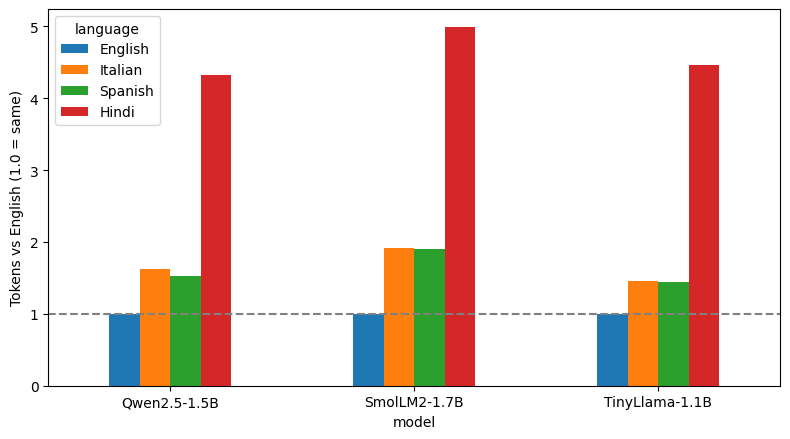

In [10]:
pivot = df.pivot(index="model", columns="language", values="parity")
pivot = pivot[["English", "Italian", "Spanish", "Hindi"]]
pivot.plot(kind="bar", figsize=(8, 4.5))
plt.axhline(1.0, color="gray", linestyle="--")
plt.ylabel("Tokens vs English (1.0 = same)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("parity_chart.png", dpi=200)
plt.show()

### 11. Save results.csv

In [11]:
df.to_csv("results.csv", index=False)
print("saved")

saved
